In [ ]:
 import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Cargar dataset desde GitHub
url = "https://raw.githubusercontent.com/microcrafted/DatasetOnlineshoppers/main/online_shoppers_intention.csv"

df = pd.read_csv(url)

print("Dataset cargado correctamente.")
print("Dimensiones:", df.shape)

Dataset cargado correctamente.
Dimensiones: (12330, 18)


In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
df.describe()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [ ]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [ ]:
df.duplicated().sum()

np.int64(125)

In [ ]:
# Revisamos las variables disponibles
print("Dimensiones del conjunto de datos:", df.shape)
print("\nTipos de datos:")
display(df.dtypes)

print("\nVariables numéricas:")
display(df.select_dtypes(include=np.number).columns.tolist())

Dimensiones del conjunto de datos: (12330, 18)

Tipos de datos:


,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Variables numéricas:


['Administrative',
 'Administrative_Duration',
 'Informational',
 'Informational_Duration',
 'ProductRelated',
 'ProductRelated_Duration',
 'BounceRates',
 'ExitRates',
 'PageValues',
 'SpecialDay',
 'OperatingSystems',
 'Browser',
 'Region',
 'TrafficType']

In [ ]:
# Selección de la variable objetivo
# ProductRelated_Duration es una variable numérica continua.
objetivo = "ProductRelated_Duration"

X = df.drop(columns=[objetivo])
y = df[objetivo]

print("Variable objetivo:", objetivo)
print("Número de variables predictoras:", X.shape[1])
print("Número de registros:", len(df))

Variable objetivo: ProductRelated_Duration
Número de variables predictoras: 17
Número de registros: 12330


In [ ]:
# Revisamos la relación de las variables numéricas con la variable objetivo
correlaciones = df.select_dtypes(include=np.number).corr()[objetivo].sort_values(ascending=False)
display(correlaciones)

,ProductRelated_Duration
ProductRelated_Duration,1.000000
ProductRelated,0.860927
Informational,0.387505
Administrative,0.373939
Administrative_Duration,0.355422
Informational_Duration,0.347364
PageValues,0.052823
OperatingSystems,0.002976
Browser,-0.007380
Region,-0.033091


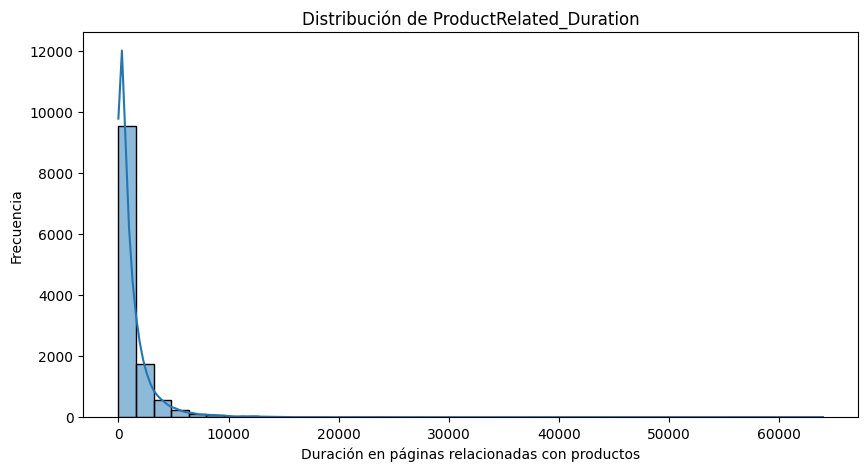

In [ ]:
# Gráfica de distribución de la variable objetivo
plt.figure(figsize=(10,5))
sns.histplot(y, bins=40, kde=True)
plt.title("Distribución de ProductRelated_Duration")
plt.xlabel("Duración en páginas relacionadas con productos")
plt.ylabel("Frecuencia")
plt.show()

In [ ]:
# Separación de variables numéricas y categóricas
columnas_categoricas = X.select_dtypes(include=["object", "bool"]).columns.tolist()
columnas_numericas = X.select_dtypes(include=np.number).columns.tolist()

print("Variables categóricas:", columnas_categoricas)
print("Variables numéricas:", columnas_numericas)

Variables categóricas: ['Month', 'VisitorType', 'Weekend', 'Revenue']
Variables numéricas: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


In [ ]:
# División de los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (9864, 17)
Datos de prueba: (2466, 17)


In [ ]:
# Preprocesamiento:
# - Variables categóricas: OneHotEncoder
# - Variables numéricas: StandardScaler
preprocesamiento = ColumnTransformer(
    transformers=[
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas),
        ("numericas", StandardScaler(), columnas_numericas)
    ]
)

modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesamiento),
        ("regresion", LinearRegression())
    ]
)

modelo.fit(X_train, y_train)

print("Modelo de regresión lineal entrenado correctamente.")

Modelo de regresión lineal entrenado correctamente.


In [ ]:
# Generar predicciones del modelo
y_pred = modelo.predict(X_test)

print("Predicciones generadas correctamente.")

Predicciones generadas correctamente.


In [ ]:
# Evaluación del modelo
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

resultados = pd.DataFrame({
    "Métrica": ["MAE", "MSE", "RMSE", "R²"],
    "Resultado": [mae, mse, rmse, r2]
})

display(resultados)

print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.4f}")

,Métrica,Resultado
0,MAE,476.827480
1,MSE,701783.941594
2,RMSE,837.725457
3,R²,0.800706


MAE: 476.83
MSE: 701783.94
RMSE: 837.73
R²: 0.8007


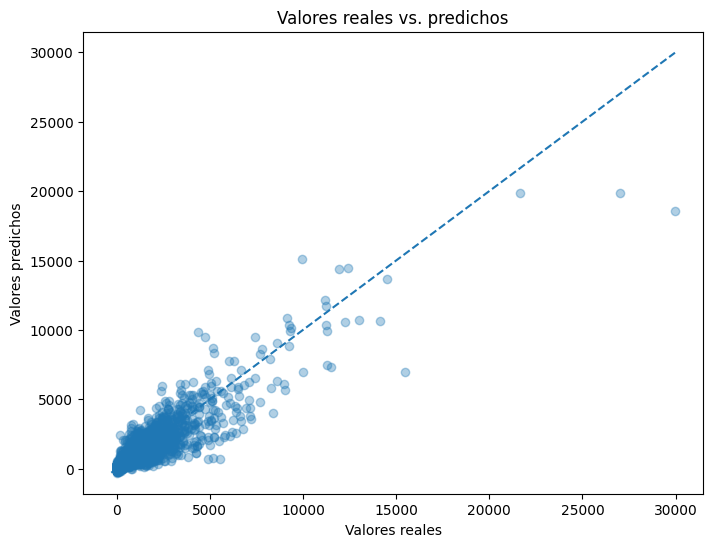

In [ ]:
# Gráfica: valores reales contra valores predichos
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.title("Valores reales vs. predichos")

limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())
plt.plot([limite_min, limite_max], [limite_min, limite_max], linestyle="--")

plt.show()

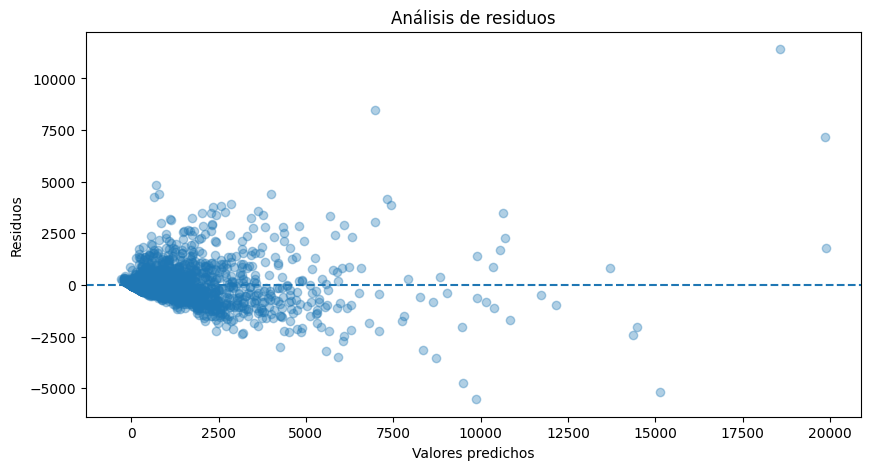

In [ ]:
# Análisis de residuos
residuos = y_test - y_pred

plt.figure(figsize=(10,5))
plt.scatter(y_pred, residuos, alpha=0.35)
plt.axhline(0, linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Análisis de residuos")
plt.show()

## Interpretación de resultados

El modelo de regresión lineal permite estimar **ProductRelated_Duration** a partir de las demás características del comportamiento de los usuarios.

Las métricas principales son:

- **MAE:** indica, en promedio, cuánto se alejan las predicciones del valor real.
- **RMSE:** penaliza más los errores grandes y permite observar qué tan grandes pueden ser las diferencias de predicción.
- **R²:** indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo. Un valor más cercano a 1 representa un mejor ajuste.

Con los datos utilizados, el modelo obtiene aproximadamente un **R² de 0.80**, por lo que explica alrededor del 80% de la variación observada en `ProductRelated_Duration` en el conjunto de prueba.

## Conclusión

El modelo de regresión lineal obtuvo un **R² de aproximadamente 0.80**, lo que indica que explica cerca del 80% de la variación de `ProductRelated_Duration`.

El **MAE** representa el error promedio de las predicciones, mientras que el **RMSE** muestra el tamaño de los errores, dando mayor importancia a los errores grandes.

En general, el modelo presenta un **ajuste considerable** y puede utilizarse para estimar la duración de las sesiones relacionadas con productos a partir de las características del comportamiento de los usuarios.